In [ ]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("gti-upm/leapgestrecog")

print("Path to dataset files:", path)

100%|██████████| 2.13G/2.13G [00:40<00:00, 56.6MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/gti-upm/leapgestrecog/versions/1


Structuring dataset directories...
Data directories successfully configured! Images copied: {'train': 18000, 'val': 2000}
Found 18000 files belonging to 10 classes.
Found 2000 files belonging to 10 classes.
Classes: ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb', '06_index', '07_ok', '08_palm_moved', '09_c', '10_down']
Epoch 1/15
563/563 ━━━━━━━━━━━━━━━━━━━━ 1198s 2s/step - accuracy: 0.8707 - loss: 0.4704 - val_accuracy: 0.2000 - val_loss: 4.3106
Epoch 2/15
563/563 ━━━━━━━━━━━━━━━━━━━━ 1228s 2s/step - accuracy: 0.9917 - loss: 0.0410 - val_accuracy: 0.8580 - val_loss: 0.3630
Epoch 3/15
563/563 ━━━━━━━━━━━━━━━━━━━━ 1197s 2s/step - accuracy: 0.9956 - loss: 0.0207 - val_accuracy: 0.9375 - val_loss: 0.3124
Epoch 4/15
563/563 ━━━━━━━━━━━━━━━━━━━━ 1179s 2s/step - accuracy: 0.9964 - loss: 0.0170 - val_accuracy: 0.8815 - val_loss: 0.2637
Epoch 5/15
563/563 ━━━━━━━━━━━━━━━━━━━━ 1164s 2s/step - accuracy: 0.9987 - loss: 0.0072 - val_accuracy: 0.7635 - val_loss: 0.6687
Epoch 6/15
563/56

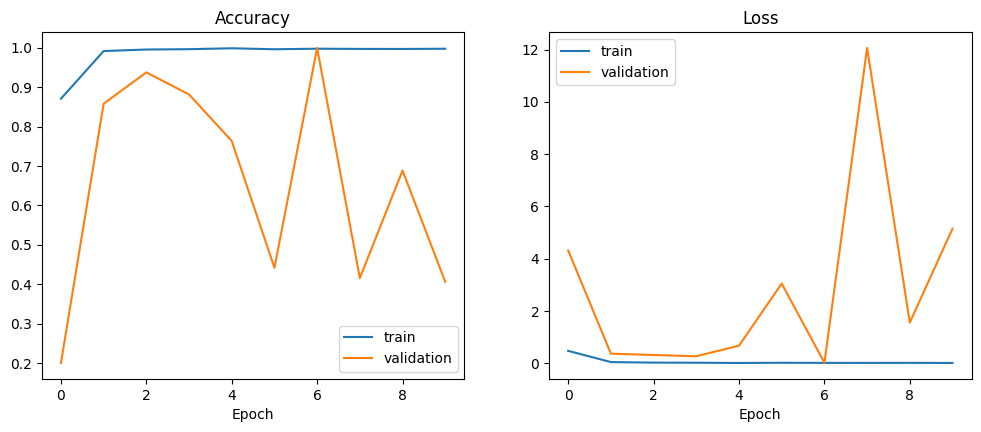

               precision    recall  f1-score   support

      01_palm       1.00      1.00      1.00       200
         02_l       1.00      1.00      1.00       200
      03_fist       1.00      1.00      1.00       200
04_fist_moved       1.00      1.00      1.00       200
     05_thumb       1.00      1.00      1.00       200
     06_index       1.00      1.00      1.00       200
        07_ok       1.00      1.00      1.00       200
08_palm_moved       1.00      0.99      1.00       200
         09_c       1.00      1.00      1.00       200
      10_down       1.00      1.00      1.00       200

     accuracy                           1.00      2000
    macro avg       1.00      1.00      1.00      2000
 weighted avg       1.00      1.00      1.00      2000

[[200   0   0   0   0   0   0   0   0   0]
 [  0 200   0   0   0   0   0   0   0   0]
 [  0   0 200   0   0   0   0   0   0   0]
 [  0   0   0 200   0   0   0   0   0   0]
 [  0   0   0   0 200   0   0   0   0   0]
 [  0   0   

In [17]:
import shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
import json

# --- 1. Restructure and Split Dataset ---
# Check if data folders already exist, otherwise create them from the downloaded path
data_dir = Path("data")
if not (data_dir / "train").exists():
    print("Structuring dataset directories...")
    # Locate downloaded cache folder
    cache_root = Path("/root/.cache/kagglehub/datasets/gti-upm/leapgestrecog/versions/1")
    dataset_root = next(p for p in cache_root.rglob("leapGestRecog") if p.is_dir())

    VAL_SUBJECT = "09"
    shutil.rmtree("data", ignore_errors=True)
    count = {"train": 0, "val": 0}

    for subject in sorted(p for p in dataset_root.iterdir() if p.is_dir()):
        split = "val" if subject.name == VAL_SUBJECT else "train"
        for gesture in sorted(p for p in subject.iterdir() if p.is_dir()):
            target = Path(f"data/{split}/{gesture.name}")
            target.mkdir(parents=True, exist_ok=True)
            for img in gesture.iterdir():
                if img.is_file():
                    shutil.copy(img, target / f"s{subject.name}_{img.name}")
                    count[split] += 1
    print("Data directories successfully configured! Images copied:", count)
else:
    print("Dataset directories already structured and present.")

# --- 2. Model Parameters and Dataset Loading ---
IMG_SIZE = (128, 128)
BATCH = 32
SEED = 42
train_ds = tf.keras.utils.image_dataset_from_directory(
    "data/train", image_size=IMG_SIZE, batch_size=BATCH, seed=SEED, label_mode="int")
val_ds = tf.keras.utils.image_dataset_from_directory(
    "data/val", image_size=IMG_SIZE, batch_size=BATCH, shuffle=False, label_mode="int")
class_names = train_ds.class_names
print("Classes:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

# --- 3. Model Architecture and Training ---
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(0.05, 0.05),
])
inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = augmentation(inputs)
x = tf.keras.layers.Rescaling(1.0 / 255)(x)
for filters in (32, 64, 128):
    x = tf.keras.layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling2D()(x)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(128, activation="relu")(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(len(class_names), activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

history = model.fit(
    train_ds, validation_data=val_ds, epochs=15,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)],
)

# --- 4. Plot Metrics ---
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="validation")
ax[0].set(title="Accuracy", xlabel="Epoch"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="validation")
ax[1].set(title="Loss", xlabel="Epoch"); ax[1].legend()
plt.show()

# --- 5. Evaluation & Export ---
y_true, y_pred = [], []
for images, labels in val_ds:
    y_pred.extend(np.argmax(model.predict(images, verbose=0), axis=1))
    y_true.extend(labels.numpy())

report = classification_report(y_true, y_pred, target_names=class_names)
cm = confusion_matrix(y_true, y_pred)
print(report)
print(cm)

Path("outputs").mkdir(exist_ok=True)
model.save("outputs/gesture_model.keras")
json.dump(class_names, open("outputs/class_names.json", "w"))
open("outputs/metrics.txt", "w").write(report + "\n\nConfusion matrix:\n" + np.array2string(cm))
print("Saved to outputs/")